JS06 Praktikum 1: Regresi Linier Sederhana (statsmodels OLS + seaborn).

Dataset: Ecommerce Customers (dataset.csv) - prediksi Yearly Amount Spent
dari Length of Membership.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("regresi_linier_sederhana.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-regresi\praktikum1


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

BASE = Path(__file__).resolve().parent
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)

In [3]:
# --- Langkah 1-4: baca & pahami data ---
data = pd.read_csv(BASE.parent / "data" / "dataset.csv")
print("shape:", data.shape)
print(data.head(3).to_string())
print(data.describe().T.to_string())

shape: (500, 8)
                       Email                                                       Address     Avatar  Avg. Session Length  Time on App  Time on Website  Length of Membership  Yearly Amount Spent
0  mstephenson@fernandez.com                835 Frank Tunnel\r\nWrightmouth, MI 82180-9605     Violet            34.497268    12.655651        39.577668              4.082621           587.951054
1          hduke@hotmail.com              4547 Archer Common\r\nDiazchester, CA 06566-8576  DarkGreen            31.926272    11.109461        37.268959              2.664034           392.204933
2           pallen@yahoo.com  24645 Valerie Unions Suite 582\r\nCobbborough, DC 99414-7564     Bisque            33.000915    11.330278        37.110597              4.104543           487.547505
                      count        mean        std         min         25%         50%         75%         max
Avg. Session Length   500.0   33.053194   0.992563   29.532429   32.341822   33.082008   


korelasi antar fitur numerik:
                       Avg. Session Length  Time on App  Time on Website  Length of Membership  Yearly Amount Spent
Avg. Session Length                 1.000       -0.028           -0.035                 0.060                0.355
Time on App                        -0.028        1.000            0.082                 0.029                0.499
Time on Website                    -0.035        0.082            1.000                -0.048               -0.003
Length of Membership                0.060        0.029           -0.048                 1.000                0.809
Yearly Amount Spent                 0.355        0.499           -0.003                 0.809                1.000


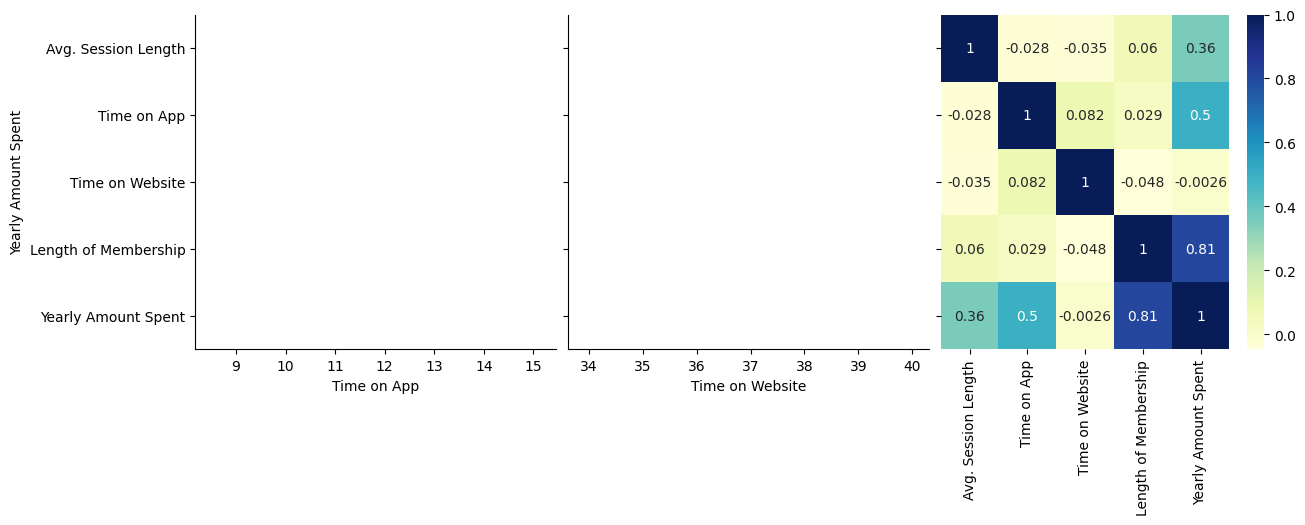

In [4]:
# --- Langkah 5: visualisasi ---
sns.pairplot(data, x_vars=["Time on App", "Time on Website", "Length of Membership"],
             y_vars="Yearly Amount Spent", height=4, aspect=1, kind="scatter")
plt.savefig(OUT / "pairplot.png", dpi=110, bbox_inches="tight")

sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.savefig(OUT / "heatmap_korelasi.png", dpi=110, bbox_inches="tight")

print("\nkorelasi antar fitur numerik:\n",
      data.corr(numeric_only=True).round(3).to_string())


parameter OLS: {'const': 265.2483, 'Length of Membership': 66.3015}
R2 train (statsmodels): 0.6688


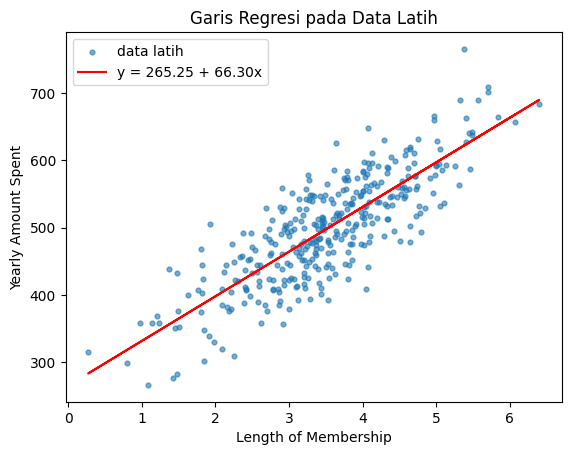

In [5]:
# --- Langkah 6: regresi linier sederhana ---
X = data["Length of Membership"]
y = data["Yearly Amount Spent"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100)

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()
print("\nparameter OLS:", lr.params.round(4).to_dict())
print("R2 train (statsmodels):", round(lr.rsquared, 4))

b0, b1 = lr.params["const"], lr.params["Length of Membership"]
plt.scatter(X_train, y_train, s=12, alpha=0.6, label="data latih")
plt.plot(X_train, b0 + b1 * X_train, "r", label=f"y = {b0:.2f} + {b1:.2f}x")
plt.title("Garis Regresi pada Data Latih")
plt.xlabel("Length of Membership")
plt.ylabel("Yearly Amount Spent")
plt.legend()
plt.savefig(OUT / "garis_regresi_train.png", dpi=110, bbox_inches="tight")

residual: mean=0.0000  std=46.6862


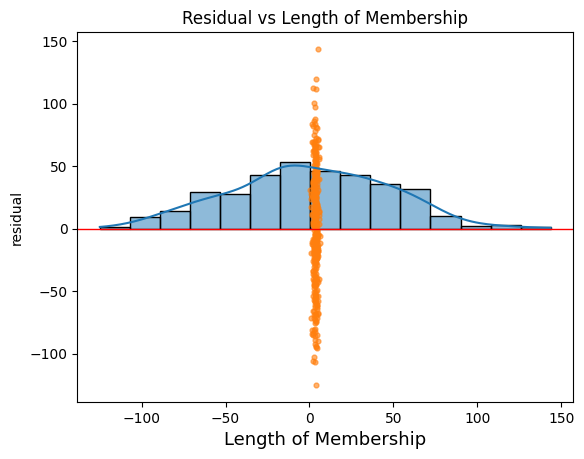

In [6]:
# --- Langkah 7: analisis residual ---
y_train_pred = lr.predict(X_train_sm)
res = y_train - y_train_pred
print("residual: mean=%.4f  std=%.4f" % (res.mean(), res.std()))

sns.histplot(res, bins=15, kde=True)
plt.title("Error Terms", fontsize=15)
plt.xlabel("y_train - y_train_pred", fontsize=13)
plt.savefig(OUT / "histogram_residual.png", dpi=110, bbox_inches="tight")

plt.scatter(X_train, res, s=12, alpha=0.6)
plt.axhline(0, color="r", lw=1)
plt.title("Residual vs Length of Membership")
plt.xlabel("Length of Membership")
plt.ylabel("residual")
plt.savefig(OUT / "scatter_residual.png", dpi=110, bbox_inches="tight")


R2 train : 0.6688
R2 test  : 0.6119


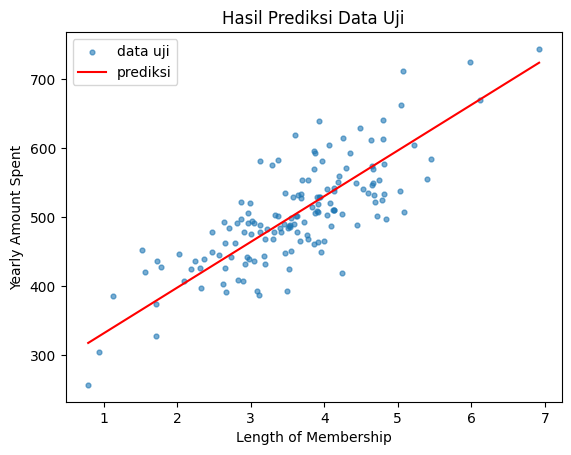

In [7]:
# --- Langkah 8-9: prediksi data uji & evaluasi ---
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)
r_squared = r2_score(y_test, y_test_pred)
print("\nR2 train :", round(lr.rsquared, 4))
print("R2 test  :", round(r_squared, 4))

plt.scatter(X_test, y_test, s=12, alpha=0.6, label="data uji")
order = X_test.argsort()
plt.plot(X_test.iloc[order], y_test_pred.iloc[order], "r", label="prediksi")
plt.title("Hasil Prediksi Data Uji")
plt.xlabel("Length of Membership")
plt.ylabel("Yearly Amount Spent")
plt.legend()
plt.savefig(OUT / "prediksi_test.png", dpi=110, bbox_inches="tight")

pd.DataFrame({"aktual": y_test, "prediksi": y_test_pred}).to_csv(
    OUT / "prediksi_test.csv", index=False)

In [8]:
# cek: manual OLS = numpy polyfit
coef = pd.Series([b0, b1], index=["const", "Length of Membership"])
assert np.allclose(np.polyfit(X_train, y_train, 1)[::-1], coef.values, atol=1e-6)
print("\n[OK] parameter OLS == numpy.polyfit derajat 1")


[OK] parameter OLS == numpy.polyfit derajat 1
